# Subgraph as compiled graph sample

In [1]:
var userHomeDir = System.getProperty("user.home");
var localRespoUrl = "file://" + userHomeDir + "/.m2/repository/";
var langgraph4jVersion = "1.9.10";

In [2]:
%%bash 
rm -rf \{userHomeDir}/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/bsc/langgraph4j

In [3]:
%dependency /add-repo local \{localRespoUrl} release|never snapshot|always
// %dependency /list-repos
%dependency /add org.slf4j:slf4j-jdk14:2.0.9
%dependency /add org.bsc.langgraph4j:langgraph4j-core:\{langgraph4jVersion}
%dependency /add net.sourceforge.plantuml:plantuml-mit:1.2024.8

%dependency /resolve

Repository local url: file:///Users/bsorrentino/.m2/repository/ added.
Adding dependency org.slf4j:slf4j-jdk14:2.0.9
Adding dependency org.bsc.langgraph4j:langgraph4j-core:1.9.10
Adding dependency net.sourceforge.plantuml:plantuml-mit:1.2024.8
Solving dependencies
Resolved artifacts count: 5
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/slf4j/slf4j-jdk14/2.0.9/slf4j-jdk14-2.0.9.jar
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/slf4j/slf4j-api/2.0.9/slf4j-api-2.0.9.jar
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/bsc/langgraph4j/langgraph4j-core/1.9.10/langgraph4j-core-1.9.10.jar
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/bsc/async/async-generator/5.2.0/async-generator-5.2.0.jar
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/net/sou

**utility to render graph respresentation in PlantUML**

In [4]:
import net.sourceforge.plantuml.SourceStringReader;
import net.sourceforge.plantuml.FileFormatOption;
import net.sourceforge.plantuml.FileFormat;
import org.bsc.langgraph4j.*;

void displayDiagram( GraphRepresentation representation ) throws IOException { 
    
    var reader = new SourceStringReader(representation.getContent());

    try(var imageOutStream = new java.io.ByteArrayOutputStream()) {

        var description = reader.outputImage( imageOutStream, 0, new FileFormatOption(FileFormat.PNG));

        var imageInStream = new java.io.ByteArrayInputStream(  imageOutStream.toByteArray() );

        var image = javax.imageio.ImageIO.read( imageInStream );

        display(  image );

    }
}

**Graph State**

In [5]:
import org.bsc.langgraph4j.prebuilt.*;
import org.bsc.langgraph4j.state.*;

public class State extends MessagesState<String> {

    public State(Map<String, Object> initData) {
        super( initData  );
    }
}

**Create action catalog**

In [6]:
import org.bsc.langgraph4j.annotation.ActionCatalogRepository;
import org.bsc.langgraph4j.annotation.ActionCatalog;
import org.bsc.langgraph4j.annotation.NodeAction;
import org.bsc.langgraph4j.annotation.EdgeCondition;
import org.bsc.langgraph4j.utils.EdgeMappings;
import org.bsc.langgraph4j.*;
import org.bsc.langgraph4j.action.*;
import static org.bsc.langgraph4j.StateGraph.END;
import static org.bsc.langgraph4j.StateGraph.START;

final var repo = ActionCatalogRepository.of( new ActionCatalog() {

    @NodeAction
    public Map<String, Object> makeNode( State state, RunnableConfig config ) {
        return Map.of("messages", config.nodePath().toString() );
    }

    @EdgeCondition( name = "continue")
    public String continueNode( State state, RunnableConfig config ) {
        return "continue";
    }
});





**Create a subgraph as compiled graph**

In [7]:


var workflowChild = new StateGraph<>(State.SCHEMA, State::new)        
                    .add( repo.node("child:step_1", "makeNode") )
                    .add( repo.node("child:step_2", "makeNode") )
                    .add( repo.node("child:step_3", "makeNode") )
                    .addEdge(START, "child:step_1")
                    .addEdge("child:step_1", "child:step_2")
                    .add(  repo.edge("child:step_2", "continue", 
                                EdgeMappings.builder()
                                    .toEND()
                                    .to( "child:step_3", "continue")
                                    .build() ))
                    .addEdge("child:step_3", END)
                    ;
var compiledWorkflowChild = workflowChild.compile();


**Create graph with a sub graph as compiled graph**
> The subgraph will be executed independently to the parent sharing its state but not `CompileConfig`

In [8]:

var workflow = new StateGraph<>(State.SCHEMA, State::new)        
                    .add( repo.node("step_1",  "makeNode") )
                    .add( repo.node("step_2",  "makeNode") )
                    .add( repo.node("step_3",  "makeNode") )
                    .addNode( "subgraph", compiledWorkflowChild )
                    .addEdge(START, "step_1")
                    .addEdge("step_1", "step_2")
                    .addEdge("step_2", "subgraph")
                    .addEdge("subgraph", "step_3")
                    .addEdge("step_3", END)
                    ;

var compiledWorkflow = workflow.compile();

compiledWorkflow.stream( GraphInput.noArgs(), RunnableConfig.empty() )
    .forEachAsync( System.out::println )
    .join();


NodeOutput{ node=__START__, state={
	messages=[]
}}
NodeOutput{ node=step_1, state={
	messages=[
	step_1
	]
}}
NodeOutput{ node=step_2, state={
	messages=[
	step_1
	step_2
	]
}}
SubGraphOutput{node=__START__, subGraphId=subgraph, state={
	messages=[
	step_1
	step_2
	]
}}
SubGraphOutput{node=child:step_1, subGraphId=subgraph, state={
	messages=[
	step_1
	step_2
	subgraph/child:step_1
	]
}}
SubGraphOutput{node=child:step_2, subGraphId=subgraph, state={
	messages=[
	step_1
	step_2
	subgraph/child:step_1
	subgraph/child:step_2
	]
}}
SubGraphOutput{node=child:step_3, subGraphId=subgraph, state={
	messages=[
	step_1
	step_2
	subgraph/child:step_1
	subgraph/child:step_2
	subgraph/child:step_3
	]
}}
SubGraphOutput{node=__END__, subGraphId=subgraph, state={
	messages=[
	step_1
	step_2
	subgraph/child:step_1
	subgraph/child:step_2
	subgraph/child:step_3
	]
}}
NodeOutput{ node=subgraph, state={
	messages=[
	step_1
	step_2
	subgraph/child:step_1
	subgraph/child:step_2
	subgraph/child:step_3
	]
}}


{
	messages=[
	step_1
	step_2
	subgraph/child:step_1
	subgraph/child:step_2
	subgraph/child:step_3
	step_3
	]
}

**Display StateGraph** as you defined

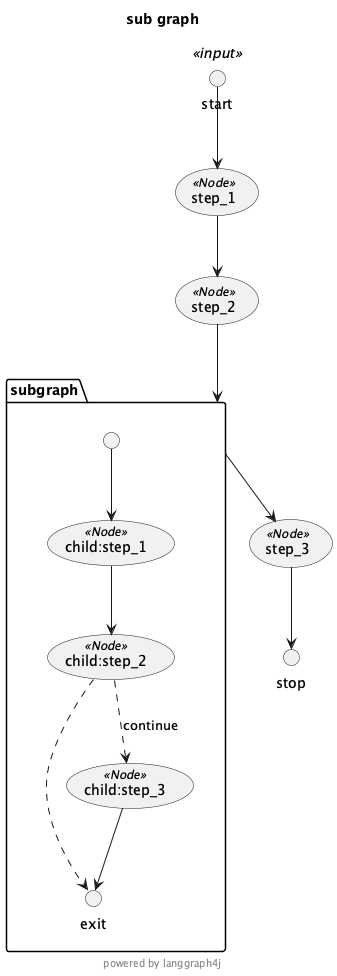

In [9]:
var representation = compiledWorkflow.getGraph( GraphRepresentation.Type.PLANTUML, "sub graph", false );

displayDiagram( representation );

**Display Compiled Graph result as graph processing**
> in such case the result will be the same of previous one because no merge will be done

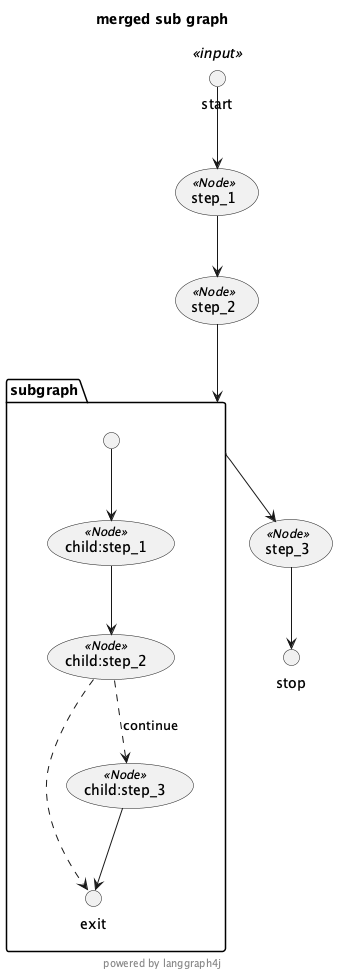

In [10]:
var representation = compiledWorkflow.getGraph( GraphRepresentation.Type.PLANTUML, "merged sub graph", false );

displayDiagram( representation );